### Assignment 3

**Name**: Christian Ulrik Niekrenz

**Student ID**: 21435375

## (1)

In [1]:
import numpy as np
import netCDF4 as nc
from sklearn.model_selection import train_test_split

In [2]:
ds = nc.Dataset("../data/SeaSurfaceTemperature_monthly_187001-202402.nc")
ds

<class 'netCDF4.Dataset'>
root group (NETCDF3_CLASSIC data model, file format NETCDF3):
    Title: Monthly version of HadISST sea surface temperature component
    description: HadISST 1.1 monthly average sea surface temperature
    institution: Met Office Hadley Centre
    source: HadISST
    reference: Rayner, N. A., Parker, D. E., Horton, E. B., Folland, C. K., Alexander, L. V., Rowell, D. P., Kent, E. C., Kaplan, A.  Global analyses of sea surface temperature, sea ice, and night marine air temperature since the late nineteenth century J. Geophys. Res.Vol. 108, No. D14, 4407 10.1029/2002JD002670
    Conventions: CF-1.0
    history: 2/4/2024 converted to netcdf from pp format
    supplementary_information: Updates and supplementary information will be available from http://www.metoffice.gov.uk/hadobs/hadisst
    comment: Data restrictions: for academic research use only. Data are Crown copyright see (http://www.opsi.gov.uk/advice/crown-copyright/copyright-guidance/index.htm)
    dime

Extract the relevant variables and check the dimensions.

In [3]:
time_var, lat_var, lon_var, sst_var = ds["time"], ds["latitude"], ds["longitude"], ds["sst"]
assert time_var.ndim == 1 and lat_var.ndim == 1 and lon_var.ndim == 1
assert sst_var.ndim == 3 and sst_var.dimensions == ("time", "latitude", "longitude")

Convert the time variable to a decimal number.

Then setup for a vectorized indexing of the data, we index 60 months of data in each block, since all of it game me memory problems.

In [4]:
time_year = np.array([d.year + (d.month - 1) / 12 for d in nc.num2date(time_var[:], time_var.units, time_var.calendar)], dtype=np.float32)
lat = lat_var[:].astype(np.float32)
lon = lon_var[:].astype(np.float32)

CHUNK = 60

def valid(block):
    data = np.ma.filled(block.astype(np.float32), np.nan)
    return np.isfinite(data) & (data > -100), data

Run the indexing by batch, each batch is vectorized using numpy.

In [5]:
n = sum(int(valid(sst_var[c:c + CHUNK])[0].sum()) for c in range(0, len(time_year), CHUNK))
X = np.empty((n, 3), dtype=np.float32)
y = np.empty(n, dtype=np.float32)
pos = 0
for c in range(0, len(time_year), CHUNK):
    mask, data = valid(sst_var[c:c + CHUNK])
    i, j, k = np.nonzero(mask)
    X[pos:pos + i.size] = np.column_stack([time_year[c + i], lat[j], lon[k]])
    y[pos:pos + i.size] = data[mask]
    pos += i.size

X.shape, y.shape

((77582832, 3), (77582832,))

Lets have a look at the index data.

In [6]:
X[1:5,], y[1:5]

(array([[1870. ,   88.5, -148.5],
        [1870. ,   88.5, -147.5],
        [1870. ,   88.5, -139.5],
        [1870. ,   88.5, -131.5]], dtype=float32),
 array([-1.8, -1.8, -1.8, -1.8], dtype=float32))

We will now split the data in a 70/15/15, we will only use a subset of the data with $10^7$ rows.

In [7]:
SUBSET_SIZE = 100000
TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
TEST_FRAC = 0.15
SEED = 2024

rng = np.random.default_rng(SEED)
idx = rng.choice(n, size=SUBSET_SIZE, replace=False)

idx_train, idx_rest = train_test_split(idx, train_size=TRAIN_FRAC, random_state=SEED)
idx_val, idx_test = train_test_split(idx_rest, train_size=VAL_FRAC / (VAL_FRAC + TEST_FRAC), random_state=SEED)

X_train, y_train = X[idx_train], y[idx_train]
X_val, y_val = X[idx_val], y[idx_val]
X_test, y_test = X[idx_test], y[idx_test]

X_train.shape, X_val.shape, X_test.shape

((70000, 3), (15000, 3), (15000, 3))

## (3)

We use a linear model first for the trend, the seasonal cycle and the spatial pattern, so it can extrapolate to 2030. XGBoost is then fitted on the residuals, with max_depth and learning_rate as the hyperparameters.

In [8]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import SplineTransformer, FunctionTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error

def month_of(Xs):
    return np.rint((Xs[:, 0] % 1) * 12)

def linear_features(Xs, n_harm):
    month = month_of(Xs)
    harmonics = [f(2 * np.pi * k * month / 12) for k in range(1, n_harm + 1) for f in (np.sin, np.cos)]
    return np.column_stack([(Xs[:, 0] - 1900) / 100, *harmonics, Xs[:, 1], Xs[:, 2]])

def make_linear(n_harm, n_knots, alpha):
    n_pass = 1 + 2 * n_harm
    ct = ColumnTransformer([
        ("trend_season", "passthrough", list(range(n_pass))),
        ("space", SplineTransformer(n_knots=n_knots, degree=3), [n_pass, n_pass + 1]),
    ])
    return make_pipeline(FunctionTransformer(lambda Xs: linear_features(Xs, n_harm)), ct, Ridge(alpha=alpha))

lin_rows, lin_models = [], []
for h in [1, 2, 3]:
    for k in [6, 10]:
        for a in [0.1, 10]:
            lin = make_linear(h, k, a).fit(X_train, y_train)
            lin_rows.append({"n_harm": h, "n_knots": k, "alpha": a,
                             "val_rmse": np.sqrt(mean_squared_error(y_val, lin.predict(X_val)))})
            lin_models.append(lin)

lin_search = pd.DataFrame(lin_rows)
best_lin = lin_models[int(lin_search.val_rmse.idxmin())]
lin_search.sort_values("val_rmse")

,n_harm,n_knots,alpha,val_rmse
10,3,10,0.1,2.575092
6,2,10,0.1,2.575255
2,1,10,0.1,2.578987
11,3,10,10.0,2.579013
7,2,10,10.0,2.579178
3,1,10,10.0,2.583036
8,3,6,0.1,2.638355
4,2,6,0.1,2.638579
0,1,6,0.1,2.642747
9,3,6,10.0,2.660890


In [9]:
import xgboost as xgb

def xgb_features(Xs):
    return np.column_stack([month_of(Xs), Xs[:, 1], Xs[:, 2]])

r_train = y_train - best_lin.predict(X_train)
r_val = y_val - best_lin.predict(X_val)
F_train, F_val = xgb_features(X_train), xgb_features(X_val)

grid = [{"max_depth": d, "learning_rate": lr} for d in [3, 6, 9, 12] for lr in [0.01, 0.05, 0.1, 0.3]]
models = []
rows = []
for params in grid:
    model = xgb.XGBRegressor(n_estimators=300, subsample=0.8, tree_method="hist",
                             eval_metric="rmse", random_state=2024, **params)
    model.fit(F_train, r_train, eval_set=[(F_train, r_train), (F_val, r_val)], verbose=False)
    curves = model.evals_result()
    train_curve = np.array(curves["validation_0"]["rmse"])
    val_curve = np.array(curves["validation_1"]["rmse"])
    best = int(val_curve.argmin())
    models.append((model, best + 1))
    rows.append({**params, "best_n_estimators": best + 1,
                 "train_rmse": train_curve[best], "val_rmse": val_curve[best]})

search = pd.DataFrame(rows)

In [10]:
search.sort_values("val_rmse")

,max_depth,learning_rate,best_n_estimators,train_rmse,val_rmse
13,12,0.05,173,0.358949,0.576389
10,9,0.10,280,0.403521,0.578103
9,9,0.05,300,0.462930,0.582270
14,12,0.10,80,0.367291,0.582384
11,9,0.30,94,0.420896,0.596468
15,12,0.30,27,0.384941,0.604892
7,6,0.30,300,0.510650,0.618012
12,12,0.01,300,0.523360,0.646698
6,6,0.10,300,0.608223,0.665097
5,6,0.05,300,0.725368,0.763205


## (4)

Here we see the validation error as a function of the parameters.

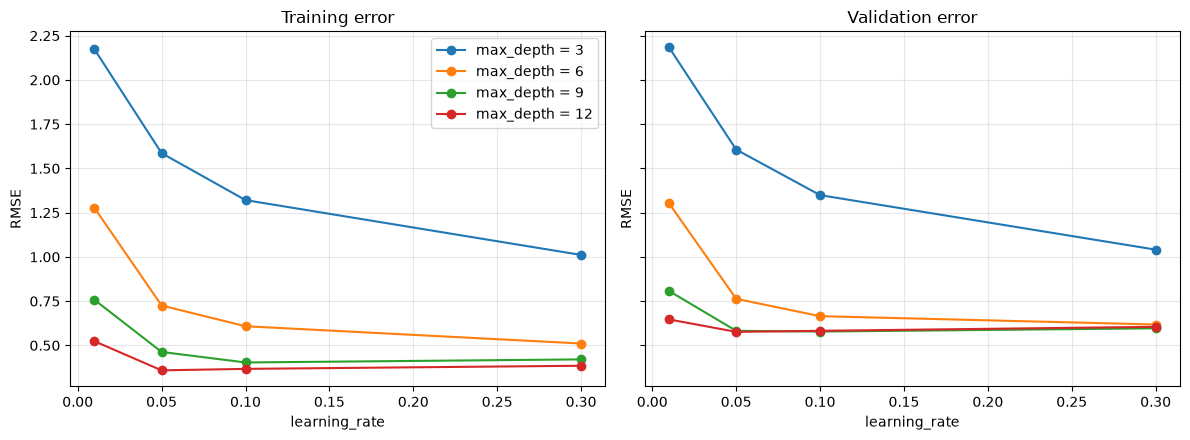

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, col, title in zip(axes, ["train_rmse", "val_rmse"], ["Training error", "Validation error"]):
    for depth, grp in search.groupby("max_depth"):
        grp = grp.sort_values("learning_rate")
        ax.plot(grp.learning_rate, grp[col], marker="o", label=f"max_depth = {depth}")
    ax.set_xlabel("learning_rate")
    ax.set_ylabel("RMSE")
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

The best model has a max_depth of 12 and a learning_rate of 0.05, with 173 trees. The validation RMSE is 0.576 and the test RMSE is 0.585, so the drop is small, which indicates we did not overfit in terms of tuning.

In [12]:
def hybrid_predict(Xs):
    return best_lin.predict(Xs) + best_model.predict(xgb_features(Xs), iteration_range=(0, best_n))

best_idx = int(search.val_rmse.idxmin())
best_model, best_n = models[best_idx]

rows = []
for name, Xs, ys in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    pred = hybrid_predict(Xs)
    rows.append({"set": name, "mse": mean_squared_error(ys, pred),
                 "rmse": np.sqrt(mean_squared_error(ys, pred)), "mae": mean_absolute_error(ys, pred)})

evaluation = pd.DataFrame(rows)
evaluation

,set,mse,rmse,mae
0,validation,0.332224,0.576389,0.399970
1,test,0.342553,0.585280,0.407803


## (5)

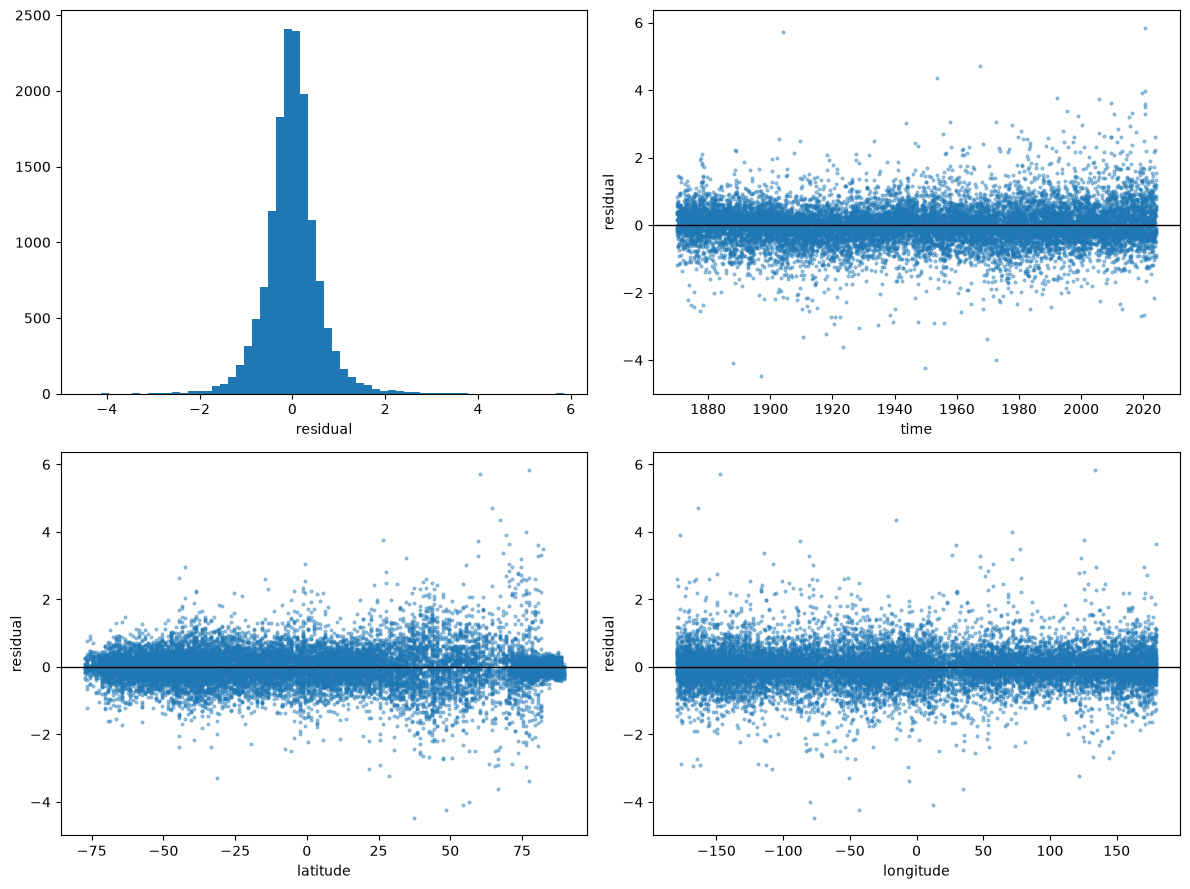

In [13]:
res = y_test - hybrid_predict(X_test)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].hist(res, bins=60)
axes[0, 0].set_xlabel("residual")
for ax, k, name in zip(axes.flat[1:], [0, 1, 2], ["time", "latitude", "longitude"]):
    ax.scatter(X_test[:, k], res, s=4, alpha=0.4)
    ax.axhline(0, color="k", lw=1)
    ax.set_xlabel(name)
    ax.set_ylabel("residual")
plt.tight_layout()
plt.show()

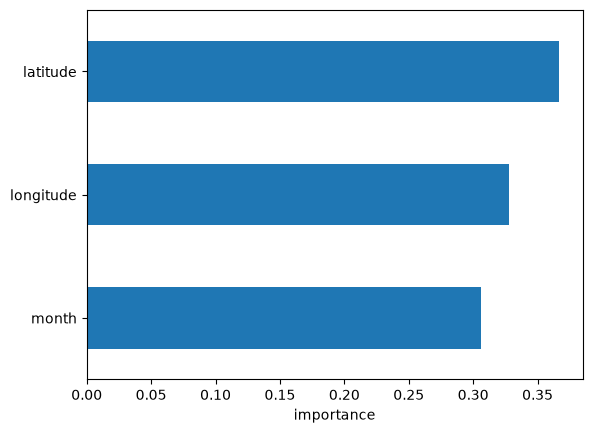

In [14]:
pd.Series(best_model.feature_importances_, index=["month", "latitude", "longitude"]).sort_values().plot.barh()
plt.xlabel("importance")
plt.show()

Forecast for Hong Kong from now until the end of 2030.

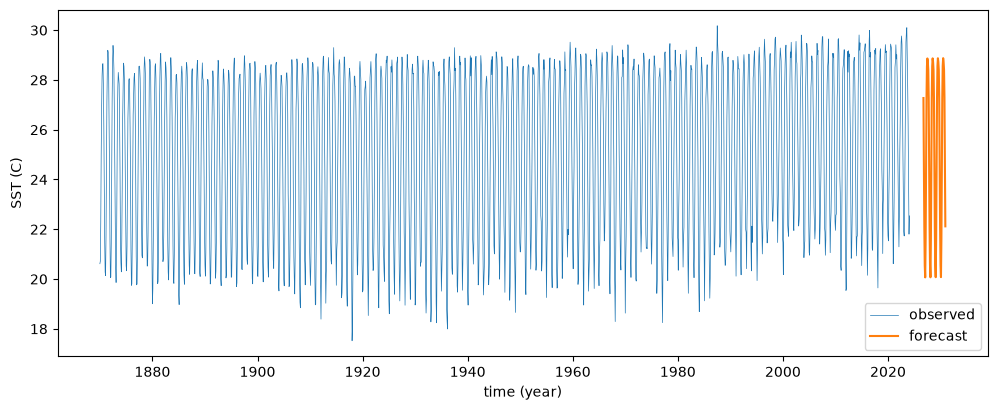

In [15]:
hi = int(np.argmin(np.abs(lat - 22.32)))
hj = int(np.argmin(np.abs(lon - 114.16)))

months = np.arange(2026 * 12 + 9, 2030 * 12 + 12)
future_t = months // 12 + (months % 12) / 12
X_future = np.column_stack([future_t, np.full(months.size, lat[hi]), np.full(months.size, lon[hj])])
forecast = hybrid_predict(X_future)

s = np.ma.filled(sst_var[:, hi, hj].astype(float), np.nan)
ok = np.isfinite(s) & (s > -100)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(time_year[ok], s[ok], lw=0.5, label="observed")
ax.plot(future_t, forecast, label="forecast")
ax.set_xlabel("time (year)")
ax.set_ylabel("SST (C)")
ax.legend()
plt.show()